# 01 · Data dan Label

**Proyek:** Firaza Custom Order Assistant (Capstone Dicoding Bootcamp Batch 15, learning path Generative AI, individu)

Notebook ini menjelaskan **data apa yang dipakai, dari mana asalnya, bagaimana labelnya ditentukan, dan mengapa data dibagi dengan cara tertentu**.
Semua sel bisa dijalankan ulang (*Run All*) dari awal. Urutan notebook: `01_data` → `02_preprocessing` → `03_model` → `04_ensemble_dan_evaluasi` → `05_inferensi_dan_genai`.

## 1. Masalah bisnis

Firaza menjual hampers dan produk personalisasi (handuk, sajadah), sekitar 99% lewat Shopee, TikTok Shop, website, dan WhatsApp.
Pesanan custom (misalnya sajadah dengan nama pengantin) masih dicatat manual, sehingga rawan salah catat nama, jumlah, tipe custom, dan status pengerjaan.

**Tugas AI di notebook ini:** dari satu pesan customer, tentukan **jenis order** (klasifikasi teks 5 kelas). Hasilnya dipakai admin sebagai *usulan*; keputusan akhir tetap di admin.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# Notebook ini berada di folder notebooks/; pindah ke root proyek agar path data/ dan src/ konsisten
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
SEED = 42
print("Root proyek:", ROOT)

Root proyek: c:\Users\asus\firaza-custom-order


## 2. Lima label dan aturan penentuannya

| Label | Kapan dipakai |
|---|---|
| **Ready Stock** | Beli atau tanya produk standar tanpa personalisasi (stok, warna, ukuran, harga, ongkir, packaging saja) |
| **Custom Sajadah** | Sajadah dengan nama, tulisan, logo, desain, font, layout, printing, atau bordir |
| **Custom Handuk** | Handuk dengan nama, inisial, logo, atau bordir |
| **Hampers** | Paket kado berisi lebih dari satu jenis item, atau menyebut hampers/parcel/seserahan/paket kado |
| **Other** | Komplain, tracking resi, info umum, reseller, ucapan terima kasih, pembatalan, pesan ambigu |

Ada 11 aturan untuk kasus perbatasan (mis. *komplain tentang order custom tetap Other*, *"tidak perlu bordir" bukan Custom*). Selengkapnya di `docs/label_guideline.md`.

In [2]:
from common import LABELS
df = pd.read_csv("data/dataset_sintetis_v3.csv")
print("Jumlah baris:", len(df), "| kolom:", list(df.columns))
df[["text", "label", "gaya_bahasa", "template_id", "split"]].head(8)

Jumlah baris: 3000 | kolom: ['id', 'text', 'label', 'produk', 'jumlah', 'nama_custom', 'acara', 'gaya_bahasa', 'sumber', 'template_id', 'template_group', 'split']


,text,label,gaya_bahasa,template_id,split
0,"p tlg krm katalog sajadh yg siap kirim, tanpa custom, thanks 😊",Ready Stock,noisy,RS17,train
1,bordr nama di handuk pesanan saya 9 hr lalu hasilnya miring mau komplain ditunggu,Other,noisy,OT11,train
2,Paket hampers perpisahan ada?,Hampers,formal,HP24,train
3,"Selamat pagi, apakah ada lowongan kerja di toko ini? Kemarin sudah sempat lihat-lihat di Shopee. Mohon inf...",Other,formal,OT19,train
4,"Selamat pagi, untuk ulang tahun, handuk 100 pcs, nanti Laras Fadhilah dipasang di pojok kiri atas. Mohon i...",Custom Handuk,formal,CH20,train
5,min alamat toko di mana ya? bisa ambil langsung? tlg info ya,Other,noisy,OT09,train
6,"Selamat siang, kardus pengiriman ukuran besar dijual terpisah ga? beli kardusnya aja. Terima kasih atas ba...",Ready Stock,formal,RS29,train
7,"assalamualaikum kak, pesanan saya kok belum sampai, resi udah 2 hari. kalau bisa dibalas hari ini ya. thanks",Other,casual,OT01,train


## 3. Data sintetis: mengapa dan bagaimana

Data asli Firaza **tidak disediakan** oleh mitra, jadi pesan customer **dibuat sendiri** oleh `src/generate_dataset.py`.
Ini keputusan yang punya konsekuensi: model belajar dari data buatan, sehingga skornya bisa lebih optimis daripada di dunia nyata. Karena itu evaluasi dirancang ketat (bagian 5).

Cara kerja generator: **template dengan slot** (produk, warna, jumlah, nama, acara, font, ...), lalu diberi **gaya bahasa** (formal, santai, atau *noisy* dengan singkatan dan typo).

In [3]:
import random
import generate_dataset as gd

tpl = gd.T["Custom Sajadah"][0]
print("Template:", tpl, "\n")
rng = random.Random(7)
for _ in range(5):
    s = gd.make_sample(rng, tpl)
    print(f"[{s['gaya_bahasa']:6s}] {s['text']}")

Template: Mau sajadah {warna_s} {jml} untuk {acara}, custom nama {nama} 

[formal] Assalamualaikum, mau sajadah krem 200 buah untuk pernikahan, custom nama Bagas. Terima kasih.
[noisy ] ka mau sajadh navy 1 buah utk pengajian custom nama bagas saya tahu toko ini dari instagram ditunggu 😊
[casual] hai firaza, mau sajadah krem 2 buah untuk lamaran, custom nama alif, ditunggu infonya
[formal] Assalamualaikum, mau sajadah abu-abu 25 buah untuk umroh, custom nama Umar Nugroho. Sebelumnya sudah follow akunnya.
[casual] kak, mau sajadah coklat 1 biji untuk ulang tahun, custom nama putri kusuma. sebelumnya udah follow akunnya. makasih ya kak


Satu template menghasilkan banyak pesan berbeda. Di bawah ini sebaran data hasil generator.

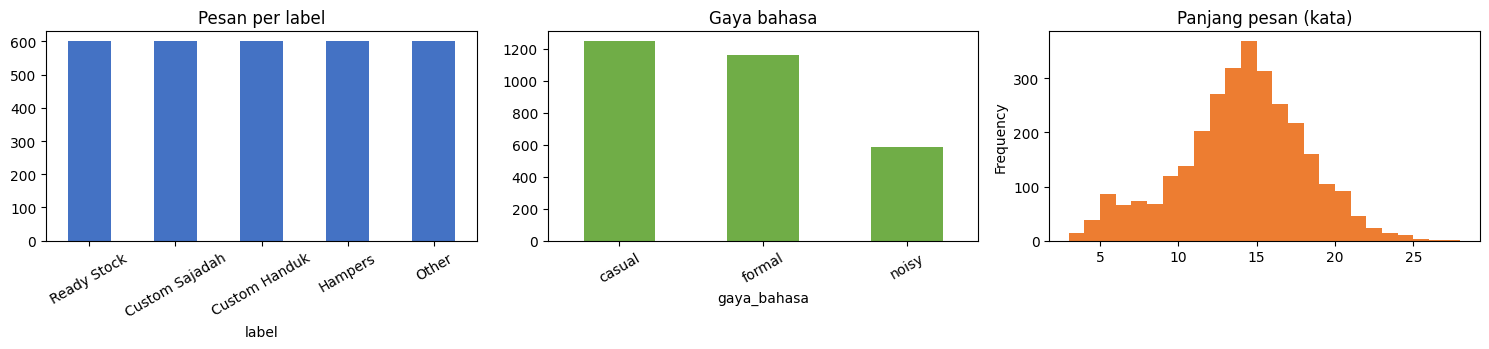

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
df.label.value_counts().reindex(LABELS).plot.bar(ax=ax[0], color="#4472c4", title="Pesan per label")
df.gaya_bahasa.value_counts().plot.bar(ax=ax[1], color="#70ad47", title="Gaya bahasa")
df.text.str.split().str.len().plot.hist(bins=25, ax=ax[2], color="#ed7d31", title="Panjang pesan (kata)")
for a in ax[:2]: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [5]:
for lab in LABELS:
    print(f"\n== {lab} ==")
    for t in df[df.label == lab].sample(3, random_state=SEED).text:
        print(" -", t)


== Ready Stock ==
 - Selamat pagi, handuk abu-abu yang biasa, ga perlu dicetak apa-apa, ready kan? Terima kasih.
 - halo kak, aku mau beli 10 sajadah tanpa nama, yang polos aja warna navy, ditunggu infonya
 - Assalamualaikum, handuk handuk tangan bahannya apa? katun semua? mau beli 30pcs. Terima kasih.

== Custom Sajadah ==
 - Selamat pagi, custom print nama Sarah Bagas Lestari di sajadah, 50pcs, posisi nama di pojok kanan bawah.
 - Assalamualaikum, mau sajadah hijau botol 10 biji untuk lamaran, custom nama Dimas. Mohon informasinya.
 - hlo kak sajadah ungu mau ditulis nama Bagas Ramadhan bisa? 25 pcs ditunggu

== Custom Handuk ==
 - halo kak, minimal order handuk bordir berapa pcs ya? ditunggu infonya
 - min, handuk untuk pengajian bisa bordir nama Budi dan tanggal tidak?
 - permisi kak, handuk mandi buat perpisahan mau diberi nama Dinda dan logo kecil, 50 pcs. ditunggu infonya

== Hampers ==
 - min, bisa tidak hampers isi sajadah custom nama Hasan dan handuk coklat? 2 box makasih ya

In [6]:
tab = df.groupby(["label", "template_group"]).template_id.nunique().unstack(fill_value=0)
tab["total template"] = tab.sum(axis=1)
tab

template_group,base,komplain,negasi,pendek,v3,total template
label,,,,,,
Custom Handuk,18,0,0,3,5,26
Custom Sajadah,18,0,0,3,5,26
Hampers,18,0,0,3,5,26
Other,18,7,0,4,8,37
Ready Stock,18,0,8,3,5,34


Tiap label punya sekitar 20-30 **template**. Grup `base` adalah template awal, `v3` kosakata yang diperluas, `negasi` dan `komplain` kasus sulit, `pendek` pesan singkat.

## 4. Test set yang ditulis sendiri

Selain data generator, ada dua kumpulan pesan yang **ditulis manual** (bukan dari template) supaya mengukur kemampuan menghadapi bahasa yang tidak berasal dari generator:

- `manual_test.csv` (100 pesan, 20 per label): dipakai untuk analisis error, jadi berstatus **data pengembangan**.
- `manual_test_blind.csv` (30 pesan, 6 per label): **dibuka satu kali** untuk menilai model final. Di notebook ini hanya dihitung jumlahnya, tidak dievaluasi.

In [7]:
man = pd.read_csv("data/manual_test.csv")
print("manual_test:", len(man), "pesan\n", man.label.value_counts().reindex(LABELS).to_dict())
if os.path.exists("data/manual_test_blind.csv"):
    bl = pd.read_csv("data/manual_test_blind.csv")
    print("\nmanual_test_blind:", len(bl), "pesan\n", bl.label.value_counts().reindex(LABELS).to_dict())

manual_test: 100 pesan
 {'Ready Stock': 20, 'Custom Sajadah': 20, 'Custom Handuk': 20, 'Hampers': 20, 'Other': 20}

manual_test_blind: 30 pesan
 {'Ready Stock': 6, 'Custom Sajadah': 6, 'Custom Handuk': 6, 'Hampers': 6, 'Other': 6}


## 5. Mengapa split per template, bukan acak?

Karena satu template menghasilkan banyak pesan yang mirip, split acak akan menaruh pesan serupa di data latih **dan** data uji. Model tinggal menghafal struktur kalimat, dan skornya menyesatkan (*kebocoran data*).
Solusinya **grouped split**: seluruh pesan dari satu template masuk ke satu split saja, sehingga data uji berisi struktur kalimat yang belum pernah dilihat. Mari buktikan dengan model sederhana (TF-IDF + Logistic Regression, tanpa preprocessing apa pun).

Macro F1 dengan split acak        : 1.000
Macro F1 dengan split per template: 0.830


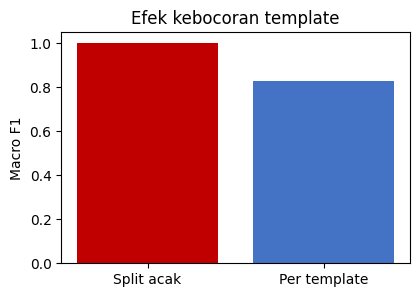

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline

def tfidf_lr():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                         LogisticRegression(C=1, max_iter=5000, random_state=SEED))

# (a) split ACAK (berpotensi bocor)
tr, te = train_test_split(df, test_size=0.2, stratify=df.label, random_state=SEED)
f_acak = f1_score(te.label, tfidf_lr().fit(tr.text, tr.label).predict(te.text), average="macro")

# (b) split PER TEMPLATE (kolom 'split' dari generator)
tr, te = df[df.split == "train"], df[df.split == "test"]
f_grup = f1_score(te.label, tfidf_lr().fit(tr.text, tr.label).predict(te.text), average="macro")

print(f"Macro F1 dengan split acak        : {f_acak:.3f}")
print(f"Macro F1 dengan split per template: {f_grup:.3f}")
plt.figure(figsize=(4.5, 3)); plt.bar(["Split acak", "Per template"], [f_acak, f_grup], color=["#c00000", "#4472c4"])
plt.ylim(0, 1.05); plt.ylabel("Macro F1"); plt.title("Efek kebocoran template"); plt.show()

**Kesimpulan:** skor di split acak jauh lebih tinggi, tetapi itu **ilusi**, karena model melihat template yang sama saat latihan. Skor di split per template yang jujur.
Karena itu seluruh evaluasi proyek memakai split per template dan **GroupKFold** (bagian 5 notebook 04).

**Pertanyaan yang mungkin ditanyakan:** *"Kenapa skormu tidak 99%?"* Jawabannya: skor 99% hanya muncul di split acak yang bocor; yang jujur adalah sekitar 0,8-0,9 pada template yang belum pernah dilihat.

➡️ Lanjut ke `02_preprocessing.ipynb`.